# 02 · Preparación de los datos

**Fase 3 de CRISP-DM.** Trazabilidad de cómo se pasa de las imágenes originales al conjunto que
usan los modelos. Cada paso se ejecuta con un comando de `src/` y este notebook **solo lee sus
resultados** (no repite el trabajo pesado):

| Paso | Comando | Resultado |
|------|---------|-----------|
| 1. Índice unificado de fuentes | `python -m src.main index` | `data/processed/index.csv` |
| 2. Formato y tamaño unificados | `python -m src.main preprocess` | `data/interim/img128/` |
| 3. Segmentación (U²-Net) | `python -m src.main segment` | `data/interim/seg128/`, `mask128/` |
| 4. Recorte centrado de la fruta | `python -m src.main crop` | `data/interim/crop128/`, `cropmask128/` |
| 5. Características φ(x) | `python -m src.main features` | `data/processed/features.npz` |
| Diagnóstico de atajos | `python -m src.evaluation.shortcut` | `experiments/results/shortcut.json` |

Decisiones y su justificación: `docs/crisp-dm.md` §3. Se genera desde `notebooks/02_preprocessing.py`
(jupytext).

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config  # noqa: E402
from src.data.preprocess import cache_path  # noqa: E402

ASSETS = ROOT / "assets" / "preparacion"
ASSETS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)
index = pd.read_csv(config.DATASET_INDEX)
print(f"{len(index)} imágenes en el índice")

21519 imágenes en el índice


## 1. Fuentes y construcción de las 3 clases

- **Kaggle `Good`** → Buena.
- **Kaggle `Bad`**: mezcla defectos leves con podredumbre → se re-anotó a mano una muestra de
  1.200 imágenes (`data/anotaciones/`, criterios en `docs/criterios_anotacion.md`).
- **Healthy-Defective-Fruits (HDF)**: manzana y mango; `fresh` → Buena, golpes/sarna/manchas →
  Defectuosa, `rot` → Podrida.
- **Fotos propias** (`propias`): conjunto de prueba externo, nunca se entrena con ellas.

In [2]:
pd.crosstab(index["fuente"], index["calidad"], margins=True, margins_name="Total")

calidad,Buena,Defectuosa,Podrida,Total
fuente,,,,
hdf,4909,2987,2000,9896
kaggle,10489,211,842,11542
propias,28,23,30,81
Total,15426,3221,2872,21519


In [3]:
pd.crosstab([index["fuente"], index["fruta"]], index["calidad"])

calidad              Buena  Defectuosa  Podrida
fuente  fruta                                  
hdf     Apple         2500        1487     1000
        Mango         2409        1500     1000
kaggle  Apple         1149          68      132
        Banana        1113          37      151
        Guava         1153          35      154
        Lime          1094          30      139
        Orange        1225          24      137
        Pomegranate   4755          17      129
propias Apple           14           7       14
        Banana           4           2        5
        Guava            2           2        3
        Lime             3           0        0
        Mango            2           7        0
        Orange           3           5        8

### Re-anotación de `Bad` (Kaggle)

Etiquetas por anotador. `Descartar` = imagen ambigua, con varias frutas o no reconocible (no entra
al índice). El acuerdo entre anotadores (kappa) se calcula con `python -m src.data.relabel` cuando
hay al menos dos anotadores.

In [4]:
anot = pd.concat([pd.read_csv(p).assign(anotador=p.stem.removeprefix("bad_"))
                  for p in sorted(config.ANNOTATIONS_DIR.glob("bad_*.csv"))])
anot["fruta"] = anot["archivo"].str.split("/").str[-2].str.split("_").str[0]
pd.crosstab([anot["anotador"], anot["fruta"]], anot["etiqueta"], margins=True, margins_name="Total")

etiqueta              Buena  Defectuosa  Descartar  Podrida  Total
anotador fruta                                                    
samuel   Apple            0          68          0      132    200
         Banana           0          37         12      151    200
         Guava            1          35         10      154    200
         Lime             0          30         31      139    200
         Orange           9          24         30      137    200
         Pomegranate      3          17         51      129    200
Total                    13         211        134      842   1200

## 2. Imágenes excluidas

Imágenes en escala de grises: solo existían en `Buena` (copias aumentadas), así que el modelo
aprendería "gris = Buena". Se excluyen al construir el índice.

In [5]:
excl = pd.read_csv(config.PROCESSED_DIR / "excluidas.csv")
excl["carpeta"] = excl["ruta"].str.split("/").str[-2]
excl.groupby(["motivo", "carpeta"]).size().rename("imágenes").to_frame()

imágenes
motivo           carpeta                   
escala de grises Pomegranate_Good      1188
                 fresh                   91
                 scab_defect             13

## 3. Grupos y splits

Las imágenes que son la misma foto o la misma fruta forman un **grupo**, y cada grupo va completo a
un solo split (train / val / test ≈ 60/20/20, por hash estable). Así ninguna fruta aparece a la vez
en entrenamiento y en evaluación.

- **Kaggle:** copias aumentadas de una misma captura (`20190820_143522_22896.jpg`).
- **HDF:** la misma fruta fotografiada cientos de veces; se agrupan las imágenes con histograma de
  color casi idéntico (`near_duplicate_groups`). Sin esto, el F1 en HDF salía 0,99 (fuga de datos).

In [6]:
sizes = index.groupby(["fuente", "grupo"]).size().rename("n").reset_index()
sizes.groupby("fuente")["n"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "mean", "50%", "90%", "99%", "max"]] \
    .rename(columns={"count": "grupos", "mean": "imágenes/grupo (media)"})

,grupos,imágenes/grupo (media),50%,90%,99%,max
fuente,,,,,,
hdf,1298.0,7.624,2.0,6.0,136.81,913.0
kaggle,7349.0,1.571,1.0,4.0,4.00,8.0
propias,81.0,1.000,1.0,1.0,1.00,1.0


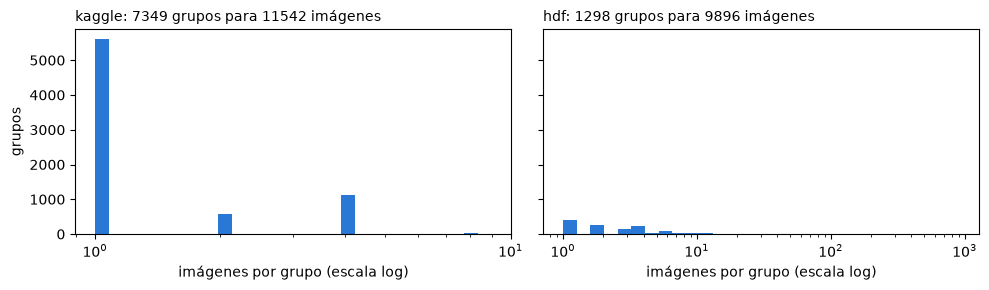

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, src in zip(axes, ["kaggle", "hdf"]):
    n = sizes.loc[sizes["fuente"] == src, "n"]
    ax.hist(n, bins=np.logspace(0, np.log10(n.max() + 1), 30), color="#2a78d6")
    ax.set_xscale("log")
    ax.set_title(f"{src}: {len(n)} grupos para {n.sum()} imágenes", loc="left", fontsize=10)
    ax.set_xlabel("imágenes por grupo (escala log)")
axes[0].set_ylabel("grupos")
plt.tight_layout()

Ejemplo: muestras de los grupos más grandes de HDF (cada fila es un grupo; todas sus imágenes van
al mismo split).

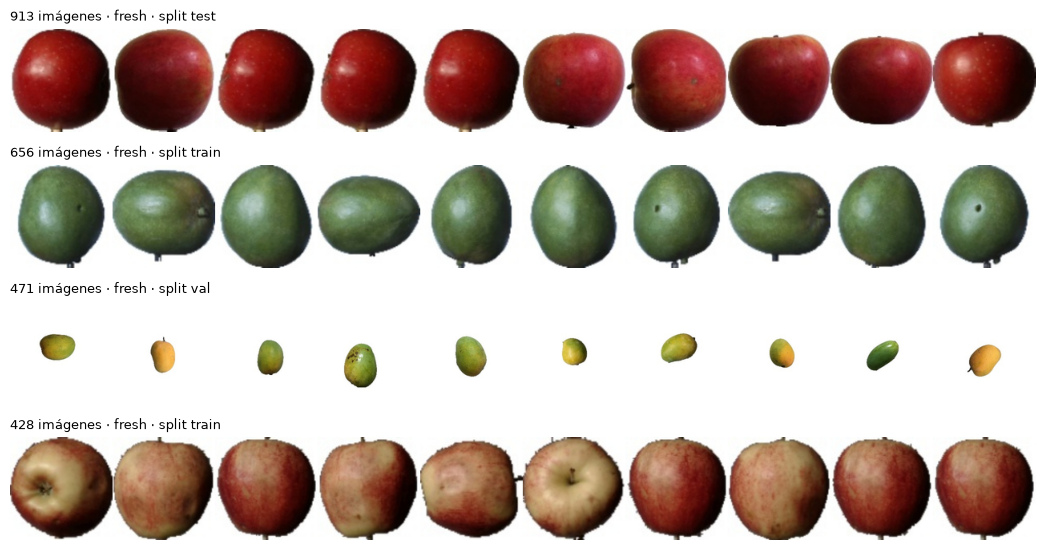

In [8]:
def contact_sheet(rows: pd.DataFrame, variant: str = "img", n: int = 10, ax=None):
    tiles = [np.asarray(Image.open(cache_path(i, variant=variant)).convert("RGB")) for i in rows["id"][:n]]
    tiles += [np.full_like(tiles[0], 255)] * (n - len(tiles))
    (ax or plt.gca()).imshow(np.hstack(tiles))


big = sizes[sizes["fuente"] == "hdf"].nlargest(4, "n")["grupo"]
fig, axes = plt.subplots(len(big), 1, figsize=(12, 1.4 * len(big)))
for ax, g in zip(axes, big):
    members = index[index["grupo"] == g].sample(frac=1, random_state=config.RANDOM_SEED)
    contact_sheet(members, ax=ax)
    ax.set_axis_off()
    ax.set_title(f"{len(members)} imágenes · {g.split('/')[-2]} · split {members['split'].iloc[0]}",
                 loc="left", fontsize=9)
plt.tight_layout()
fig.savefig(ASSETS / "casi_duplicados_hdf.png", dpi=150)
fig.savefig(ASSETS / "casi_duplicados_hdf.svg")

In [9]:
pd.crosstab(index["split"], index["calidad"], margins=True, margins_name="Total") \
    .reindex(["train", "val", "test", "externa", "Total"])

calidad,Buena,Defectuosa,Podrida,Total
split,,,,
train,8577,1865,1853,12295
val,3109,846,535,4490
test,3712,487,454,4653
externa,28,23,30,81
Total,15426,3221,2872,21519


In [10]:
# Comprobación: ningún grupo cruza splits.
assert (index.groupby("grupo")["split"].nunique() == 1).all()
print("OK: cada grupo está en un solo split")

OK: cada grupo está en un solo split


## 4. Del archivo original a la entrada de los modelos

1. **original preprocesada** (`img`): orientación, RGB, 128×128 sin deformar.
2. **segmentada** (`seg`): U²-Net separa la fruta y el fondo pasa a blanco.
3. **máscara** (`mask`): sirve para forma y tamaño.
4. **recortada** (`crop`): caja de la máscara centrada y reescalada → mismo zoom para todas.
   Es la entrada de todos los modelos.

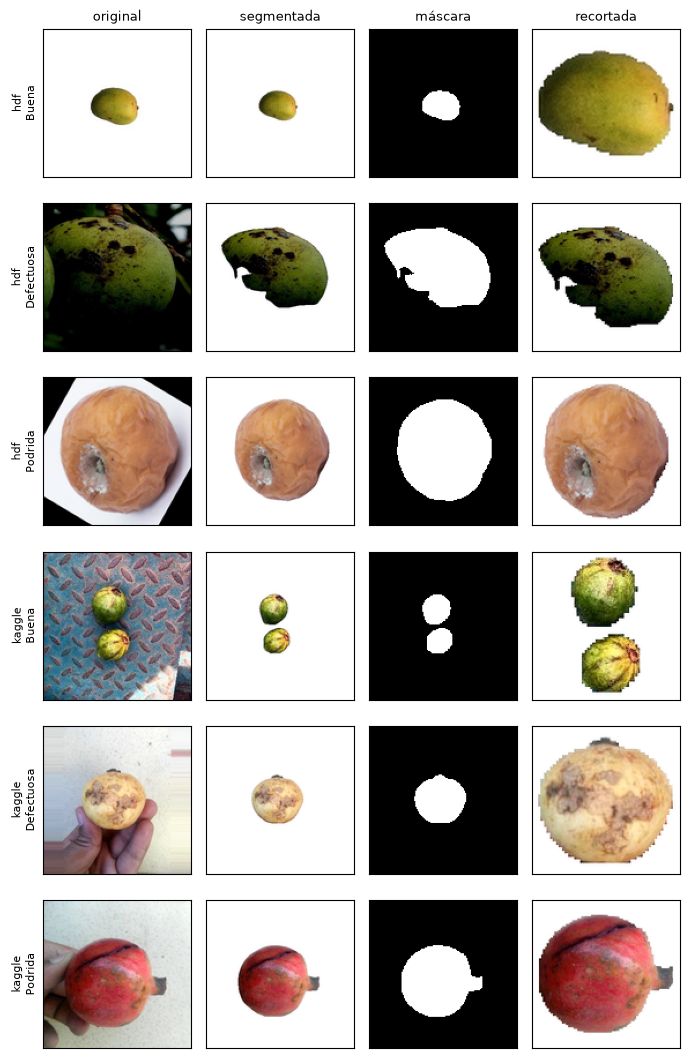

In [11]:
variants = ["img", "seg", "mask", "crop"]
examples = (index[index["split"] != "externa"]
            .groupby(["fuente", "calidad"]).sample(1, random_state=config.RANDOM_SEED))
fig, axes = plt.subplots(len(examples), len(variants), figsize=(7, 1.8 * len(examples)))
for row_axes, (_, r) in zip(axes, examples.iterrows()):
    for ax, v in zip(row_axes, variants):
        ax.imshow(Image.open(cache_path(r["id"], variant=v)), cmap="gray")
        ax.set_xticks([]), ax.set_yticks([])
    row_axes[0].set_ylabel(f"{r['fuente']}\n{r['calidad']}", fontsize=8)
for ax, v in zip(axes[0], ["original", "segmentada", "máscara", "recortada"]):
    ax.set_title(v, fontsize=9)
plt.tight_layout()

Calidad de la segmentación: fracción de la imagen ocupada por la fruta. Con menos de 2 % se
considera fallida y se conserva la imagen original.

In [12]:
stats = pd.read_csv(config.INTERIM_DIR / "seg_stats.csv").merge(index[["id", "fuente", "calidad"]], on="id")
print(f"Segmentaciones fallidas (< 2 %): {(stats['area'] < 0.02).sum()} de {len(stats)}")
stats.groupby(["fuente", "calidad"])["area"].describe(percentiles=[0.05, 0.5, 0.95])[["count", "5%", "50%", "95%"]]

Segmentaciones fallidas (< 2 %): 39 de 21519


count     5%    50%    95%
fuente  calidad                                 
hdf     Buena        4909.0  0.049  0.444  0.503
        Defectuosa   2987.0  0.099  0.305  0.472
        Podrida      2000.0  0.048  0.196  0.392
kaggle  Buena       10489.0  0.055  0.131  0.305
        Defectuosa    211.0  0.061  0.140  0.273
        Podrida       842.0  0.066  0.152  0.297
propias Buena          28.0  0.191  0.517  0.628
        Defectuosa     23.0  0.280  0.533  0.633
        Podrida        30.0  0.246  0.554  0.633

## 5. Diagnóstico de atajos

Regresiones logísticas que solo ven información "prohibida": el **fondo** (anillo exterior de la
imagen) o la **silueta** (área, posición y forma de la máscara, sin color). Si predicen la clase
mejor que el azar, un modelo puede aprender eso en lugar de la calidad. F1-macro en validación.

In [13]:
sc = pd.DataFrame(json.load(open(config.RESULTS_DIR / "shortcut.json", encoding="utf-8")))
sc.pivot(index="prueba", columns="subconjunto", values="f1_atajo") \
    .reindex(["fondo (original)", "fondo (segmentada)", "silueta", "silueta (recortada)"])[["todas", "kaggle", "hdf"]] \
    .assign(azar=sc.groupby("prueba")["f1_azar"].first())

subconjunto,todas,kaggle,hdf,azar
prueba,,,,
fondo (original),0.650,0.518,0.757,0.339
fondo (segmentada),0.180,0.357,0.328,0.339
silueta,0.476,0.333,0.445,0.339
silueta (recortada),0.472,0.322,0.374,0.339


- El fondo original predecía la clase (sobre todo en HDF); tras segmentar queda al nivel del azar.
- La silueta en HDF (encuadre/zoom) baja con el recorte centrado.
- La silueta en "todas" sigue por encima del azar porque la forma delata la fruta y cada fuente
  tiene otra mezcla de frutas y clases; no es un atajo de captura.

## 6. Características para ML tradicional

φ(x) ∈ ℝ⁶⁸ calculado solo con los píxeles de la fruta: color (histogramas HSV, media, desviación),
textura (LBP, GLCM) y forma (área, circularidad, solidez, momentos de Hu).

{'color': 38, 'textura': 18, 'forma': 12} → (21519, 68)


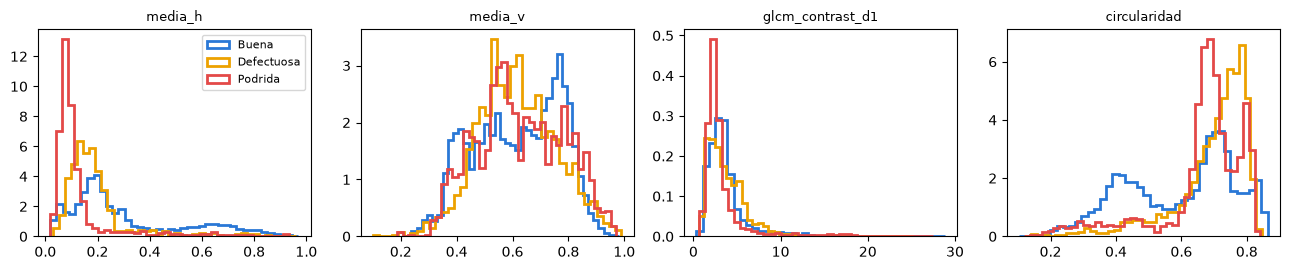

In [14]:
from src.features.extract_features import FEATURE_GROUPS, feature_names, load_features  # noqa: E402

X, rows = load_features()
feats = pd.DataFrame(X, columns=feature_names())
feats["calidad"] = [r["calidad"] for r in rows]
feats = feats[[r["split"] != "externa" for r in rows]]  # solo datos de entrenamiento/evaluación
print(FEATURE_GROUPS, "→", X.shape)

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, col in zip(axes, ["media_h", "media_v", "glcm_contrast_d1", "circularidad"]):
    for q, color in zip(config.QUALITY_CLASSES, ["#2a78d6", "#eda100", "#e34948"]):
        ax.hist(feats.loc[feats["calidad"] == q, col], bins=40, density=True, histtype="step", lw=2,
                color=color, label=q)
    ax.set_title(col, fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()

## 7. Fotos propias (prueba externa)

Tomadas por el equipo; se procesan con exactamente el mismo pipeline. Aquí solo se muestran:
**no se evalúan hasta tener el modelo final** (Fase 5), para que sigan siendo una prueba externa.

In [15]:
own = index[index["fuente"] == "propias"]
pd.crosstab(own["fruta"], own["calidad"], margins=True, margins_name="Total")

calidad,Buena,Defectuosa,Podrida,Total
fruta,,,,
Apple,14,7,14,35
Banana,4,2,5,11
Guava,2,2,3,7
Lime,3,0,0,3
Mango,2,7,0,9
Orange,3,5,8,16
Total,28,23,30,81


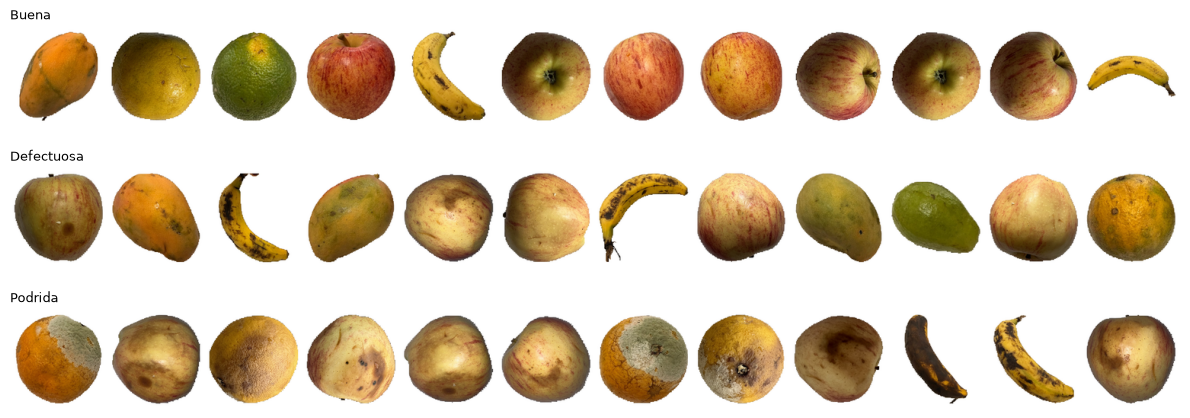

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 4.5))
for ax, q in zip(axes, config.QUALITY_CLASSES):
    contact_sheet(own[own["calidad"] == q].sample(frac=1, random_state=config.RANDOM_SEED), variant="crop",
                  n=12, ax=ax)
    ax.set_axis_off()
    ax.set_title(q, loc="left", fontsize=9)
plt.tight_layout()